---
title: "The next three dekads, October-December 2023"
subtitle: "Subseasonal rainfall forecasts for Indonesia from GEFSv12, issued at the end of each dekad and calibrated with CCA and PCR through CPT"
description: "Forecast total rainfall for the next one, two and three dekads from each issue date in late 2023, using GEFSv12 calibrated with CCA and PCR against CHIRPS v3.0, and measure skill by lead over 2000-2018."
execute:
  enabled: false
---

A subseasonal forecast is issued on a date and looks ahead: here, at the end of
each dekad (*dasarian*: days 1-10, 11-20 and 21 to the end of a month), it gives
the **total rainfall of the next three dekads**. Dekads are the unit BMKG,
Indonesia's meteorological agency, uses for its rainfall early warnings, and the
CHIRPS v3.0 archive used throughout this tutorial is stored in them.

This notebook builds that product for October-December 2023 with **GEFSv12**, the
model in PyCPT's subseasonal catalog, calibrates it with CCA and PCR through CPT,
and measures how skill changes from one dekad ahead to three. The design (issue
rule, lead windows, model, years, settings, scores) was fixed before any skill was
computed.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine, the CHIRPS v3.0 dekadal archive
from the monthly case, and internet access the first time: about 290 GEFSv12 files
(about 1.4 GB) from the IRI Data Library, no key needed. The six CPT fits take
about ten minutes.
:::

## 1. Issue dates, leads and training starts

**In real time** a forecast is issued on the last day of a dekad, from the GEFSv12
run started at 00 UTC that day. Dekad +1 begins the next day, dekad +2 eleven or
twelve days later, dekad +3 twenty-one or twenty-two days later. GEFSv12 runs every
day, so the 2023 forecasts use exactly these issue dates.

**For training**, GEFSv12's hindcasts (2000-2018) start only on Wednesdays. For each
October-December target dekad and each lead, the training sample uses the one
Wednesday whose start falls in a 7-day window around the real-time offset:

| Lead | Real-time offset (days) | Training window (days) | Latest model day used |
| --- | --- | --- | --- |
| Dekad +1 | 1 | 1 to 7 | 17 |
| Dekad +2 | 11 or 12 | 8 to 14 | 24 |
| Dekad +3 | 21 or 22 | 18 to 24 | 34 |

Every window holds exactly one Wednesday, so all three leads are trained on the same
171 target dekads (9 per year) and scored on the same targets. Lead 1 is the one
compromise: its training starts are 1-7 days before the target, its real-time start
1 day before, so training is on average slightly harder than real use. A fourth
dekad would need model days beyond 35. The design table comes from the tutorial's
[GEFS download script](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/download_gefs_dekads.py),
which the cell imports so the two cannot disagree.

In [1]:
from pathlib import Path
import datetime as dt
import json
import shutil
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
from cptcore import canonical_correlation_analysis, principal_components_regression

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.country_grid import aggregate_country_rainfall
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import download_gefs_dekads as gefs_source
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-dekads"
training_years = list(gefs_source.TRAINING_YEARS)
leads = [1, 2, 3]
predictand_extent = {"west": 94, "east": 142, "south": -12, "north": 7}
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=17,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))

design = pd.DataFrame(gefs_source.design())
print(f"{design.dekad.nunique()} target dekads; {design[design.kind == 'hindcast'].start.nunique()} hindcast starts, "
      f"{design[design.kind == 'forecast'].start.nunique()} 2023 issue dates; latest model day used: {design.last_day.max()}")
design.groupby(["kind", "lead"]).agg(targets=("dekad", "size"), first_offset=("first_day", "min"),
                                     last_offset=("first_day", "max"), latest_day=("last_day", "max"))

180 target dekads; 278 hindcast starts, 11 2023 issue dates; latest model day used: 34


targets  first_offset  last_offset  latest_day
kind     lead                                                
forecast 1           9             1            1          11
         2           9            11           12          21
         3           9            21           22          31
hindcast 1         171             1            7          17
         2         171             8           14          24
         3         171            18           24          34

## 2. Observations: dekad totals

The predictand is CHIRPS v3.0 dekad rainfall from the local archive, on the
tutorial's 0.25° Indonesia land grid ([chapter 3](../learn/03-local-observations.ipynb)).
The archive stores each dekad's time bounds and keeps exact zeros; the cell checks
the bounds before use.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
stamps = pd.DatetimeIndex(source.time.values)
index = np.flatnonzero(stamps.year.isin(training_years + [gefs_source.FORECAST_YEAR]) & stamps.month.isin([10, 11, 12]))
bounds = pd.DatetimeIndex(source.time_bnds.isel(time=index).values.ravel()).values.reshape(-1, 2)
first_day, end_day = pd.DatetimeIndex(bounds[:, 0]), pd.DatetimeIndex(bounds[:, 1])
targets = design.drop_duplicates("dekad").sort_values("dekad")
assert (first_day.date == targets.dekad.values).all() and (end_day.date == targets.end.values).all()
print(f"{len(index)} dekads with stored bounds matching the design; lengths {sorted(set((end_day - first_day).days))} days")

box = predictand_extent
start = time.monotonic()
native = (source.precip.sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))
          .isel(time=index).load())
print(f"Read {dict(native.sizes)} in {time.monotonic() - start:.0f} s; negative values: {int((native < 0).sum())}")

records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(native.lon, native.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": native.lat, "lon": native.lon})
print("Indonesian pixel-dekads at exactly 0 mm:", int(((native == 0) & country).sum()))

centres_y = box["south"] + 0.125 + np.arange(76) * 0.25
centres_x = box["west"] + 0.125 + np.arange(192) * 0.25
obs = xr.concat([aggregate_country_rainfall(native.isel(time=i, drop=True), country, 5, minimum_coverage=0.99)
                 .precipitation.rename({"lat": "Y", "lon": "X"}).assign_coords(Y=centres_y, X=centres_x)
                 .sortby("Y", ascending=False) for i in range(native.sizes["time"])],
                dim=pd.Index(first_day, name="T"))
train = obs["T"].dt.year < 2019
cells = obs.where(train, drop=True).notnull().all("T")
obs = obs.where(cells)
weights = np.cos(np.deg2rad(obs["Y"])) * cells
print(f"Cells complete in all {int(train.sum())} training dekads: {int(cells.sum())}")

180 dekads with stored bounds matching the design; lengths [10, 11] days


Read {'time': 180, 'lat': 380, 'lon': 960} in 47 s; negative values: 0


Indonesian pixel-dekads at exactly 0 mm: 160629


Cells complete in all 171 training dekads: 3240


## 3. Model: daily GEFSv12 to dekad totals

Each start is one request to the IRI Data Library for the predictor box
85-155°E, 20°S-20°N (as in the seasonal cases), all members and daily slots up to
34.5 days. Files already on disk are reused when they open and cover every model
day their targets need. Hindcasts store each day's amount (kg m⁻², which is mm);
forecasts store a rate (kg m⁻² s⁻¹), converted with 86,400 seconds per day. The units
are read from each file's `units` attribute, which the download script checks for
every start.

In [3]:
raw_dir = case_root / "gefs"
raw_dir.mkdir(parents=True, exist_ok=True)
need = gefs_source.needed_starts()
fetched = sum(gefs_source.ensure(raw_dir, kind, start, last_day) > 0 for (kind, start), last_day in need.items())
print(f"{len(need)} starts checked; downloaded now: {fetched}")

factor = {"hindcast": 1.0, "forecast": 86400.0}
fields, missing, negative = [], 0, 0
for row in design.itertuples():
    slots = np.arange(row.first_day, row.first_day + row.days) + 0.5      # day d after the start is slot L = d + 0.5
    with xr.open_dataset(gefs_source.path_for(raw_dir, row.kind, row.start), decode_timedelta=False) as ds:
        daily = ds["pr"].isel(S=0, drop=True).sel(L=slots).load()
    missing += int((~np.isfinite(daily)).sum())
    negative += int((daily < 0).sum())
    total = (daily * factor[row.kind]).sum("L", skipna=False).mean("M", skipna=False)
    fields.append(total.assign_coords(lead=row.lead, T=pd.Timestamp(row.dekad)))
assert missing == 0 and negative == 0
gefs = (xr.concat(fields, dim="sample").set_index(sample=["lead", "T"]).unstack("sample")
        .transpose("lead", "T", "Y", "X").sortby("Y", ascending=False))
assert (gefs["T"].values == obs["T"].values).all()
print(f"GEFS dekad totals {dict(gefs.sizes)}; missing values {missing}, negative values {negative}")

289 starts checked; downloaded now: 0


GEFS dekad totals {'lead': 3, 'T': 180, 'Y': 41, 'X': 71}; missing values 0, negative values 0


## 4. Anomalies, and three things CPT needs

October-December rainfall rises through the season, so a correlation over all
dekads would partly score that rise. Model and observations are therefore turned
into **anomalies** from the 2000-2018 mean of the same calendar dekad (and, for the
model, the same lead). The same means are subtracted from the 2023 values, and the
observed mean is added back at the end to give a forecast **total**.

These means include the year held out in cross-validation. For correlations that
makes no difference: leaving a year out of its own dekad mean multiplies every
anomaly by the same factor (19/18), so the correlations come out identical either
way. Inside CPT's cross-validated fits it shifts each fold's training anomalies
slightly; that effect was not measured.

Three adjustments let CPT fit these samples, each found by a failed run while
preparing the case:

1. **Placeholder years.** With the real dekad dates (steps of 10 or 11 days, then a
   jump to the next October) the CPT process stopped while reading its input. The
   samples get placeholder years, 1801 onwards, all labelled 1-10 October, in their
   original order, as PyCPT's own `redate` does for its in-sample fit
   ([chapter 4](../learn/04-evaluate-models.ipynb)). Cross-validation depends only
   on the order.
2. **Field name.** CPT refused negative values in fields named `precipitation`
   ("Data contain negative values when zero-bound is set"); the anomaly fields are
   named `anomaly`.
3. **Latitude order.** `cptcore` expects latitudes from north to south.

The cross-validation window of 17 samples leaves out the held-out dekad and 8 on
each side, so a training fit never sees another dekad of the same season.

In [4]:
key = obs["T"].dt.strftime("%m-%d")
y_clim = obs.where(train, drop=True).groupby(key.where(train, drop=True)).mean("T")
y_anom = obs.groupby(key) - y_clim
x_anom = {}
for lead in leads:
    x = gefs.sel(lead=lead, drop=True)
    x_anom[lead] = x.groupby(key) - x.where(train, drop=True).groupby(key.where(train, drop=True)).mean("T")

area = lambda f: float(f.where(cells).weighted(weights).mean(("Y", "X")))
seasonal = y_clim.weighted(weights).mean(("Y", "X"))
print("2000-2018 mean dekad rainfall over Indonesian cells (mm):",
      dict(zip(seasonal["strftime"].values, np.round(seasonal.values, 1).tolist())))


def cpt_ready(a, real_times, first_year):
    years = first_year + np.arange(len(real_times))
    a = a.drop_vars([c for c in a.coords if c not in ("T", "Y", "X")]).sel(T=real_times)
    a = a.assign_coords(T=pd.to_datetime([f"{y}-10-05" for y in years]))
    a = a.assign_coords(Ti=("T", pd.to_datetime([f"{y}-10-01" for y in years])),
                        Tf=("T", pd.to_datetime([f"{y}-10-10" for y in years])))
    a = a.transpose("T", "Y", "X").rename("anomaly")
    a.attrs = {"units": "mm", "missing": -999.0, "long_name": "dekad rainfall anomaly"}
    return a


train_T = obs["T"].values[train.values]
test_T = obs["T"].values[~train.values]
Y = cpt_ready(y_anom.where(obs.notnull()), train_T, 1801)
inputs = {lead: (cpt_ready(x_anom[lead], train_T, 1801), cpt_ready(x_anom[lead], test_T, 1990)) for lead in leads}
print("Y", dict(Y.sizes), "| X", dict(inputs[1][0].sizes), "| F", dict(inputs[1][1].sizes))

2000-2018 mean dekad rainfall over Indonesian cells (mm): {'10-01': 69.9, '10-11': 69.8, '10-21': 87.5, '11-01': 83.8, '11-11': 92.6, '11-21': 94.6, '12-01': 95.0, '12-11': 95.3, '12-21': 109.2}


Y {'T': 171, 'Y': 76, 'X': 192} | X {'T': 171, 'Y': 41, 'X': 71} | F {'T': 9, 'Y': 41, 'X': 71}


## 5. Six fits

CCA (3 predictor and 3 predictand EOFs, 2 CCA modes) and PCR (3 predictor EOFs) at
each lead, through `cptcore`, the layer PyCPT's `evaluate_models` calls. PyCPT's own
subseasonal driver is not used: in this version it fails on a fresh download and
has no PCR.

In [5]:
results = {}
for lead in leads:
    X, F = inputs[lead]
    for method, function, method_settings in [("CCA", canonical_correlation_analysis, cca_settings),
                                              ("PCR", principal_components_regression, settings)]:
        folder = case_root / f"cpt-lead{lead}-{method.lower()}"
        shutil.rmtree(folder, ignore_errors=True)
        folder.mkdir(parents=True)
        start = time.monotonic()
        hindcast, forecast, skill = function(X, Y, F=F, **method_settings, cpt_kwargs={"outputdir": folder})[:3]
        results[lead, method] = dict(hindcast=hindcast, forecast=forecast, skill=skill, seconds=time.monotonic() - start)
print("Seconds per fit:", {f"{lead}-{m}": round(r["seconds"]) for (lead, m), r in results.items()})


def clean(a):
    return a.where(a > -999).reindex(Y=Y["Y"], X=Y["X"], method="nearest", tolerance=1e-3)


def plain(a, times):
    return a.drop_vars([c for c in a.coords if c not in ("T", "C", "Y", "X")]).assign_coords(T=times)


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


y_plain = Y.drop_vars(["Ti", "Tf"])
rows = []
for (lead, method), r in results.items():
    det = plain(clean(r["hindcast"].deterministic), y_plain["T"].values)
    rows.append({"lead": lead, "method": method, "hindcast values below 0 (%)": round(float((det < 0).sum() / det.notnull().sum() * 100), 1),
                 "largest gap, CPT vs recomputed correlation": float(np.nanmax(np.abs((clean(r["skill"].pearson) - pearson(det, y_plain)).where(cells).values)))})
pd.DataFrame(rows).set_index(["lead", "method"])

Seconds per fit: {'1-CCA': 108, '1-PCR': 64, '2-CCA': 99, '2-PCR': 60, '3-CCA': 106, '3-PCR': 62}


hindcast values below 0 (%)  \
lead method                                
1    CCA                            50.2   
     PCR                            50.2   
2    CCA                            50.4   
     PCR                            50.7   
3    CCA                            52.5   
     PCR                            52.0   

             largest gap, CPT vs recomputed correlation  
lead method                                              
1    CCA                                   7.391589e-07  
     PCR                                   7.502959e-07  
2    CCA                                   8.722155e-07  
     PCR                                   8.732644e-07  
3    CCA                                   7.971018e-07  
     PCR                                   8.243340e-07

Both checks pass when the hindcasts keep negative anomalies (nothing was clipped at
zero) and CPT's correlation map equals a correlation recomputed from its own
cross-validated hindcasts.

## 6. Skill by lead

Cross-validated scores over the 171 training dekads, as area-weighted means over
the 3,240 cells (weights: cosine of latitude):

- **Pearson correlation** of hindcast and observed anomalies; 0 is no linear relationship.
- **2AFC**: the chance (in %) that the hindcasts rank two different dekads in the observed order; 50% is no skill.
- **ROC area** for below- and above-normal dekads; 0.5 is no skill.

The **raw GEFS** baseline is the model's own anomaly, interpolated from 1° to the
cell centres, correlated with the observed anomalies. It involves no fitting, so it
pays none of the cost that cross-validation charges the calibrated forecasts.

In [6]:
raw_pearson = {lead: pearson(inputs[lead][0].interp(Y=Y["Y"], X=Y["X"]).drop_vars(["Ti", "Tf"]), y_plain).where(cells)
               for lead in leads}
rows = []
for (lead, method), r in results.items():
    rows.append({"lead": lead, "method": method, "Pearson": area(clean(r["skill"].pearson)),
                 "2AFC (%)": area(clean(r["skill"].two_alternative_forced_choice)),
                 "ROC below normal": area(clean(r["skill"].roc_area_below_normal)),
                 "ROC above normal": area(clean(r["skill"].roc_area_above_normal))})
for lead in leads:
    rows.append({"lead": lead, "method": "raw GEFS", "Pearson": area(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

Pearson  2AFC (%)  ROC below normal  ROC above normal
lead method                                                         
1    CCA         0.367    63.377             0.701             0.683
     PCR         0.364    63.269             0.697             0.682
     raw GEFS    0.433       NaN               NaN               NaN
2    CCA         0.321    61.388             0.670             0.659
     PCR         0.321    61.493             0.671             0.660
     raw GEFS    0.334       NaN               NaN               NaN
3    CCA         0.183    57.603             0.621             0.603
     PCR         0.184    57.338             0.615             0.600
     raw GEFS    0.212       NaN               NaN               NaN

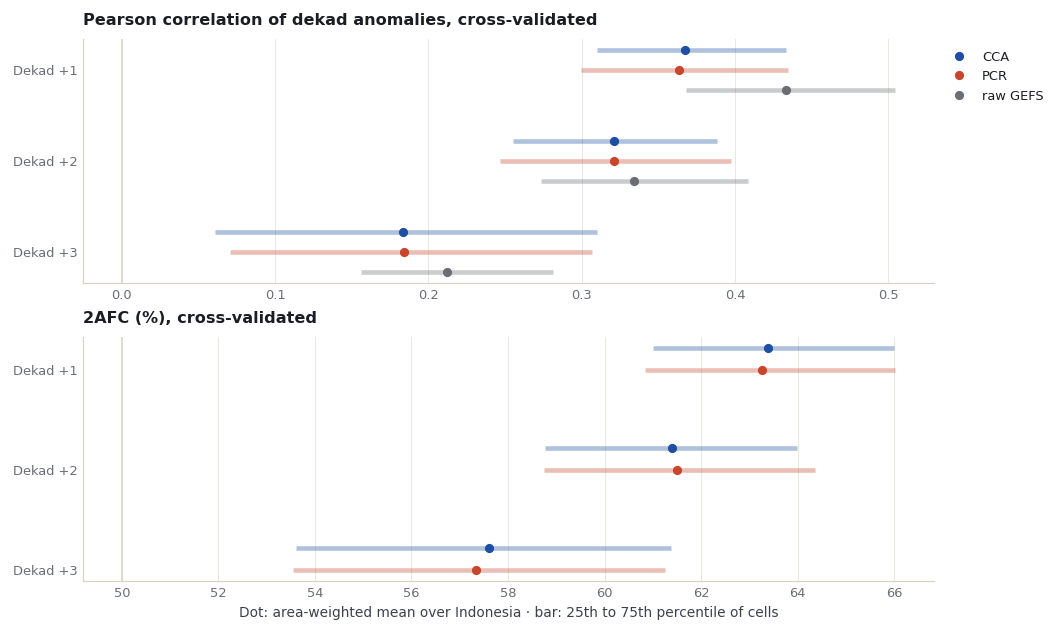

In [7]:
def quartiles(field):
    return np.nanpercentile(field.where(cells).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw GEFS": figures.MUTED}
panels = [("Pearson", "pearson", "Pearson correlation of dekad anomalies, cross-validated", 0),
          ("2AFC (%)", "two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 5.6), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw GEFS" and metric != "pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw GEFS" else clean(results[lead, method]["skill"][metric])
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [f"Dekad +{lead}" for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of cells")
assets = repo / "docs/assets/dekad-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
for old in assets.glob("*.png"):
    old.unlink()
fig.savefig(assets / "skill-by-lead.png")
plt.show()

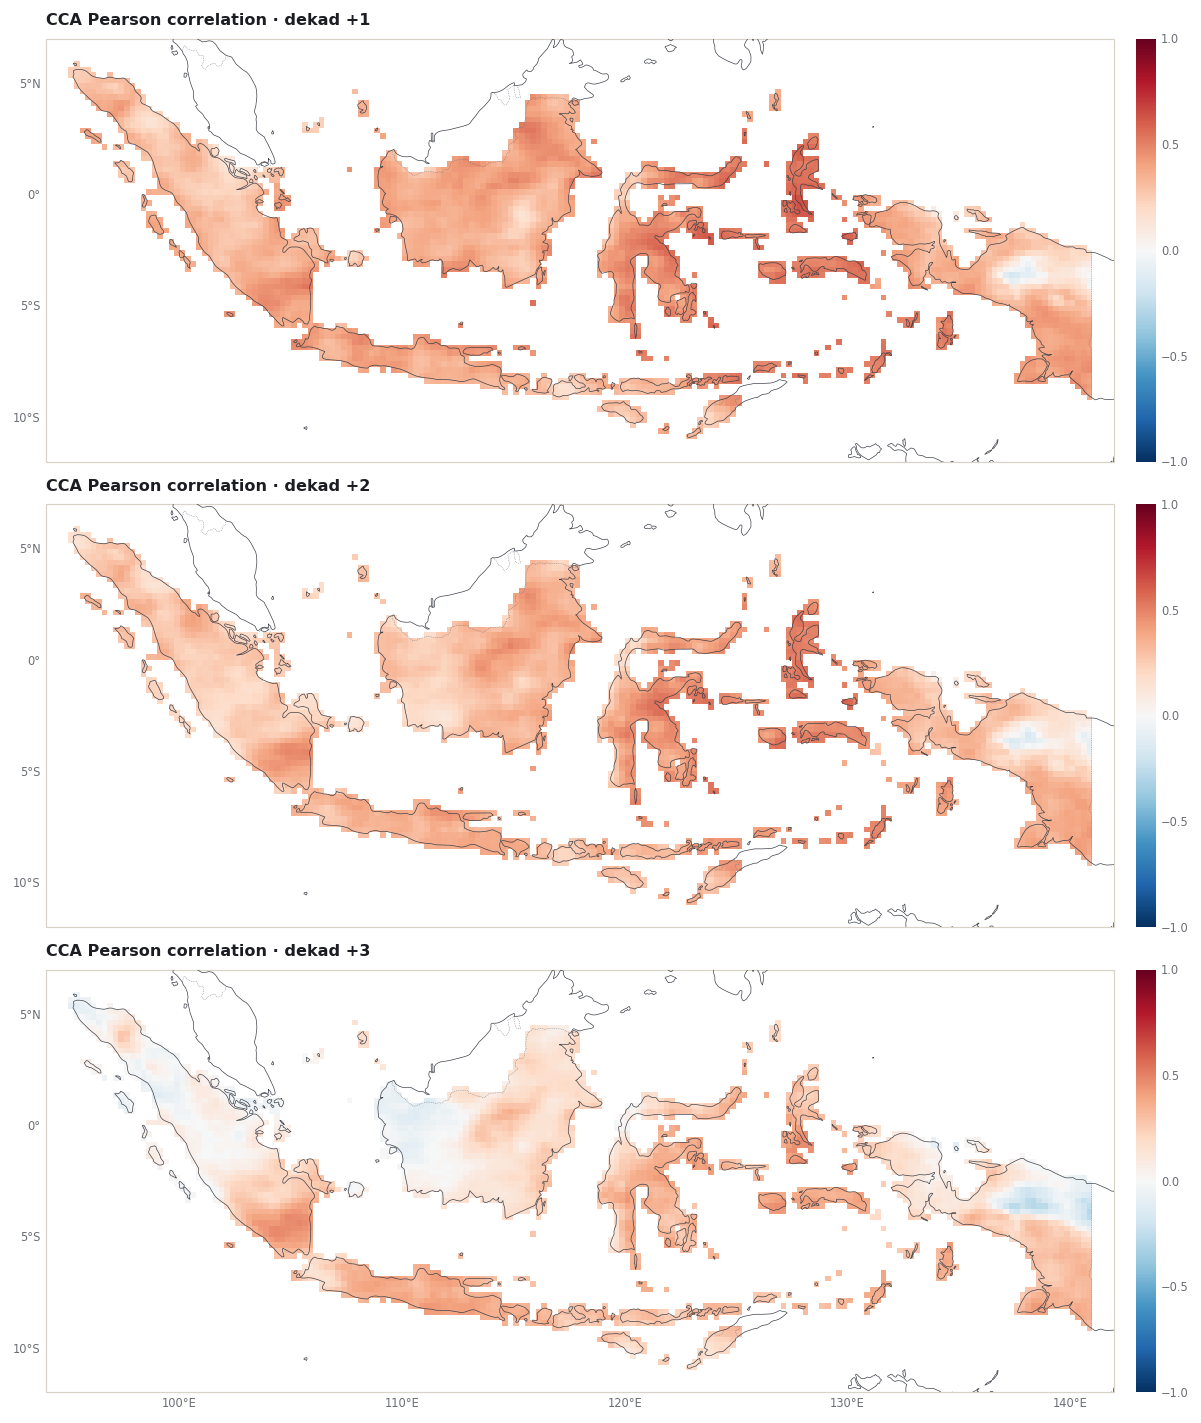

In [8]:
predictand_box = figures.extent_of(predictand_extent)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, clean(results[lead, "CCA"]["skill"].pearson).where(cells), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · dekad +{lead}")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 7. The 2023 forecasts, as issued

Each issue date gives a forecast for the next three dekads. A forecast **total** is
the observed 2000-2018 mean for that calendar dekad plus the calibrated anomaly;
where that sum is negative it is set to zero, and the cell counts how often.

CPT also gives tercile probabilities. It defines the categories from the training
samples it was given, all 171 dekads together, so the observed category uses the
same definition: at each cell, below the 33rd or above the 67th percentile of the
171 training anomalies (NumPy's `hazen` rule, as in
[chapter 5](../learn/05-probabilistic-forecasts.ipynb)).

In [9]:
obs_2023 = obs.sel(T=test_T)
obs_2023_anom = y_anom.sel(T=test_T).where(obs_2023.notnull())
clim_2023 = y_clim.sel(strftime=[pd.Timestamp(t).strftime("%m-%d") for t in test_T]).drop_vars("strftime").assign_coords(
    strftime=("strftime", test_T)).rename(strftime="T").transpose("T", "Y", "X")
lower, upper = np.quantile(Y.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(lower, coords={"Y": Y["Y"], "X": Y["X"]}, dims=("Y", "X"))
upper = lower.copy(data=upper)
observed_category = xr.where(obs_2023_anom < lower, 0, xr.where(obs_2023_anom > upper, 2, 1)).where(obs_2023_anom.notnull())

forecast = {}
clipped = 0
for (lead, method), r in results.items():
    anomaly = plain(clean(r["forecast"].deterministic), test_T).where(cells)
    total = clim_2023 + anomaly
    clipped += int((total < 0).sum()) if method == "CCA" else 0
    probability = plain(clean(r["forecast"].probabilistic), test_T)
    most_likely = probability.fillna(-1).argmax("C").where(probability.notnull().all("C") & cells)
    forecast[lead, method] = dict(anomaly=anomaly, total=total.clip(min=0), probability=probability,
                                  most_likely=most_likely, top=probability.max("C").where(cells))
print("CCA forecast totals below zero before clipping (cell-dekads, all leads):", clipped)

issues = {}
for r in design[design.kind == "forecast"].sort_values(["start", "lead"]).itertuples():
    issues.setdefault(r.start, []).append((int(r.lead), pd.Timestamp(r.dekad)))
print(f"{len(issues)} issue dates in 2023:")
for start, items in issues.items():
    print(f"  issued {start:%d %b}: " + ", ".join(f"dekad +{lead} = {d:%d %b}" for lead, d in sorted(items)))

CCA forecast totals below zero before clipping (cell-dekads, all leads): 778
11 issue dates in 2023:
  issued 10 Sep: dekad +3 = 01 Oct
  issued 20 Sep: dekad +2 = 01 Oct, dekad +3 = 11 Oct
  issued 30 Sep: dekad +1 = 01 Oct, dekad +2 = 11 Oct, dekad +3 = 21 Oct
  issued 10 Oct: dekad +1 = 11 Oct, dekad +2 = 21 Oct, dekad +3 = 01 Nov
  issued 20 Oct: dekad +1 = 21 Oct, dekad +2 = 01 Nov, dekad +3 = 11 Nov
  issued 31 Oct: dekad +1 = 01 Nov, dekad +2 = 11 Nov, dekad +3 = 21 Nov
  issued 10 Nov: dekad +1 = 11 Nov, dekad +2 = 21 Nov, dekad +3 = 01 Dec
  issued 20 Nov: dekad +1 = 21 Nov, dekad +2 = 01 Dec, dekad +3 = 11 Dec
  issued 30 Nov: dekad +1 = 01 Dec, dekad +2 = 11 Dec, dekad +3 = 21 Dec
  issued 10 Dec: dekad +1 = 11 Dec, dekad +2 = 21 Dec
  issued 20 Dec: dekad +1 = 21 Dec


One issue date in full: the forecast issued on 31 October 2023 for the three
dekads of November, against what was observed. One column, forecast above observed
for each dekad.

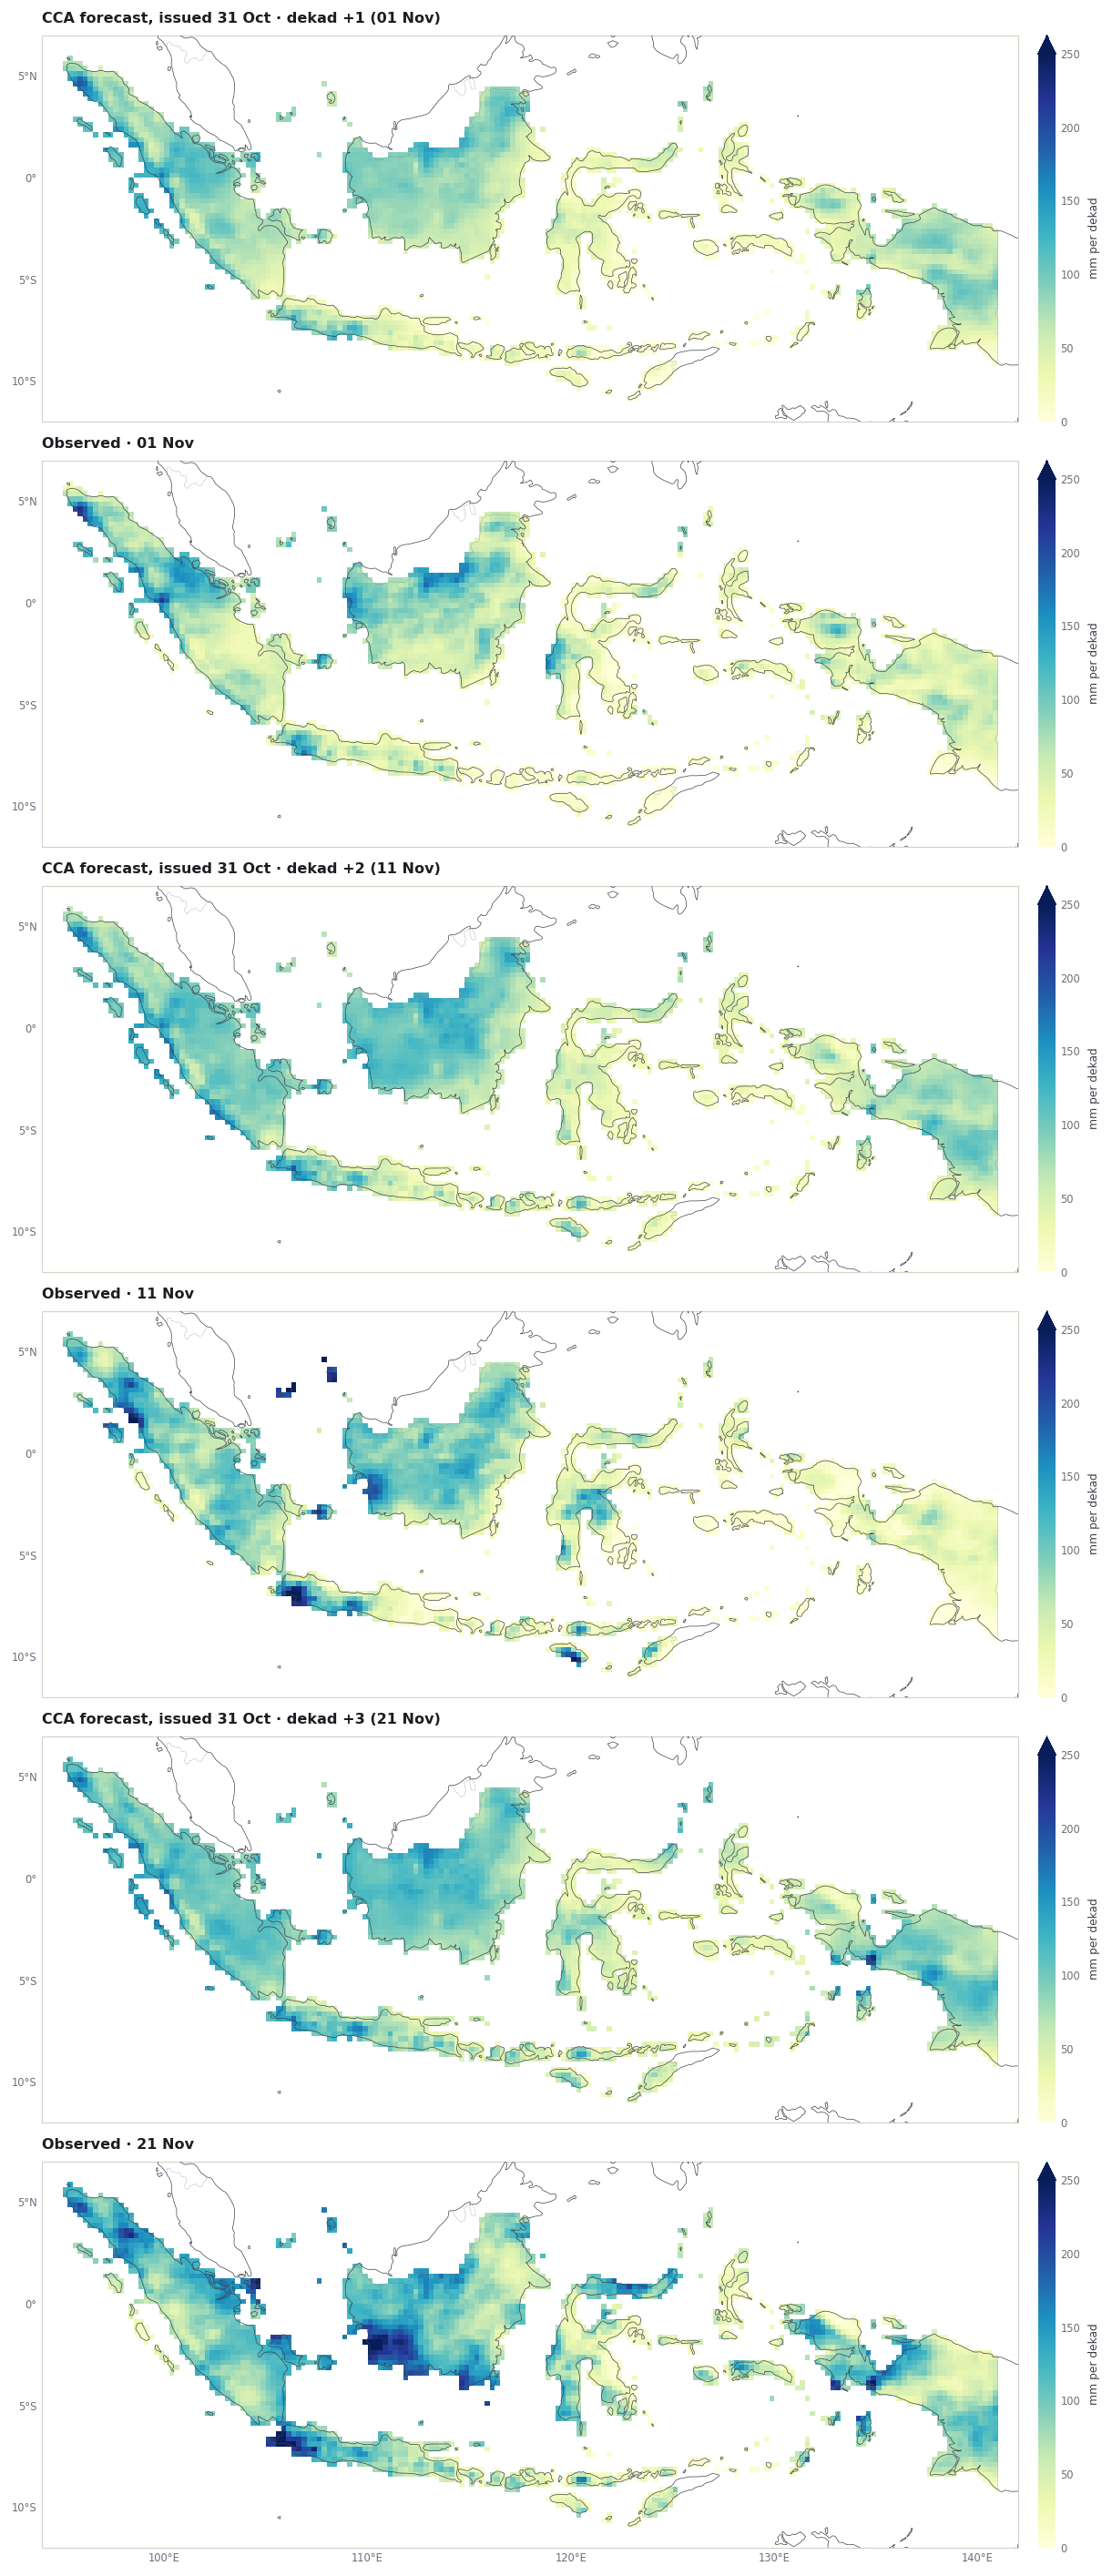

In [10]:
example = pd.Timestamp("2023-10-31").date()
items = sorted(issues[example])
fig, grid = figures.stacked([figures.map_height(predictand_box)] * 6)
row = 0
for lead, target in items:
    for label, field in [(f"CCA forecast, issued 31 Oct · dekad +{lead} ({target:%d %b})", forecast[lead, "CCA"]["total"].sel(T=target)),
                         (f"Observed · {target:%d %b}", obs_2023.sel(T=target))]:
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == 5)
        image = figures.draw_field(ax, field, cmap="YlGnBu", vmin=0, vmax=250)
        ax.set_title(label)
        figures.colorbar(fig, image, ax, "mm per dekad", extend="max")
        row += 1
fig.savefig(assets / "issued-2023-10-31.png")
plt.show()

Over all nine October-December dekads, for each lead: the area-weighted forecast
total against the observed total, then scores over every cell and dekad
(area-weighted):

- **Hit rate**: share where the most likely category was the one observed. The
  reference is the share of the most frequent observed category.
- **RPSS 2023**: ranked probability skill score against climatological odds
  (33/34/33%); above 0 is closer to what happened. Nine dekads of one season, not
  a skill estimate.
- **RMSE 2023**: error of the forecast totals in mm per dekad.

In [11]:
w3 = (weights * obs_2023_anom.notnull()).astype(float)
shares = {name: float(w3.where(observed_category == k, 0).sum() / w3.sum() * 100)
          for k, name in enumerate(["below normal", "near normal", "above normal"])}
print("Observed categories, share of area x dekads (%):", {k: round(v, 1) for k, v in shares.items()})


def rps(probability, category):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(category <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


rows = []
for (lead, method), f in forecast.items():
    w = w3.where(f["most_likely"].notnull(), 0)
    climatology = xr.DataArray([33.0, 34.0, 33.0], dims="C", coords={"C": f["probability"]["C"]}).broadcast_like(f["probability"])
    rows.append({"lead": lead, "method": method,
                 "hit rate (%)": float(w.where(f["most_likely"] == observed_category, 0).sum() / w.sum() * 100),
                 "RPSS 2023": float(1 - rps(f["probability"], observed_category).weighted(w).mean()
                                    / rps(climatology, observed_category).weighted(w).mean()),
                 "RMSE 2023 (mm)": float(np.sqrt(((f["total"] - obs_2023) ** 2).weighted(w).mean())),
                 "mean forecast (mm)": float(f["total"].weighted(w).mean()),
                 **{f"forecast {name} (%)": float(w.where(f["most_likely"] == k, 0).sum() / w.sum() * 100)
                    for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
print(f"Observed mean: {float(obs_2023.weighted(w3).mean()):.1f} mm per dekad; "
      f"reference hit rate (most frequent observed category): {max(shares.values()):.1f}%")
forecast_2023.round(2)

Observed categories, share of area x dekads (%): {'below normal': 54.5, 'near normal': 31.1, 'above normal': 14.4}


Observed mean: 66.8 mm per dekad; reference hit rate (most frequent observed category): 54.5%


hit rate (%)  RPSS 2023  RMSE 2023 (mm)  mean forecast (mm)  \
lead method                                                                
1    CCA            53.91       0.18           36.73               77.67   
     PCR            53.25       0.17           36.99               77.45   
2    CCA            45.41       0.08           39.71               81.06   
     PCR            45.42       0.08           40.21               80.79   
3    CCA            51.03       0.09           39.15               79.79   
     PCR            49.93       0.10           39.32               79.67   

             forecast below (%)  forecast near (%)  forecast above (%)  
lead method                                                             
1    CCA                  63.27              12.62               24.11  
     PCR                  63.12              12.44               24.44  
2    CCA                  56.34              18.01               25.65  
     PCR                  57.90              16.76               25.34  
3    CCA                  71.11              13.40               15.50  
     PCR                  66.95              12.05               21.01

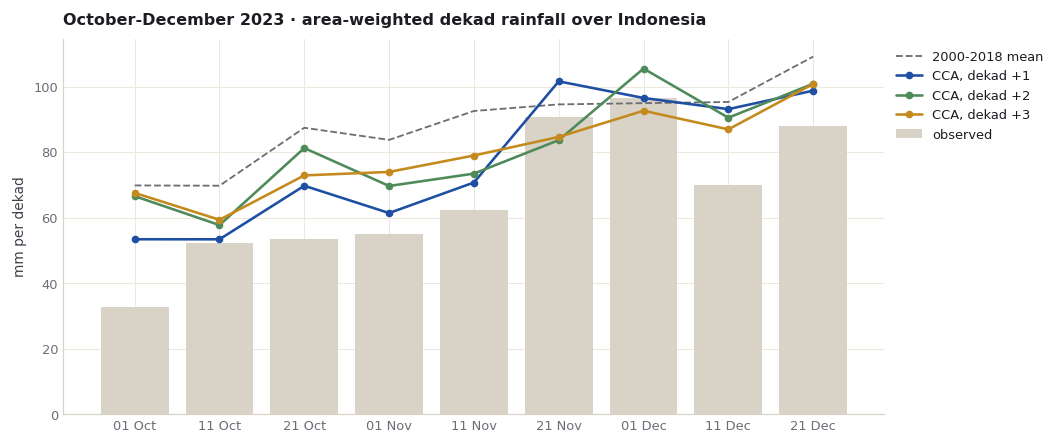

In [12]:
labels = [f"{pd.Timestamp(t):%d %b}" for t in test_T]
observed_series = obs_2023.weighted(weights).mean(("Y", "X"))
clim_series = clim_2023.where(cells).weighted(weights).mean(("Y", "X"))
fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 3.9), layout="constrained")
ax.bar(np.arange(9), observed_series, color=figures.LINE, label="observed")
ax.plot(np.arange(9), clim_series, color=figures.MUTED, linestyle="--", linewidth=1.2, label="2000-2018 mean")
for lead, colour in zip(leads, [figures.ACCENT, figures.GREEN, figures.GOLD]):
    s = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X"))
    ax.plot(np.arange(9), s, "o-", color=colour, markersize=4, label=f"CCA, dekad +{lead}")
ax.set_xticks(np.arange(9), labels)
ax.set_ylabel("mm per dekad")
ax.set_title("October-December 2023 · area-weighted dekad rainfall over Indonesia")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "ond-2023-series.png")
plt.show()

## 8. Save the results

Tables and figures for the story page, and one compact JSON file for its interactive
maps and charts: every field is stored only at the 3,240 Indonesian cells, in the
order of a shared cell list.

In [13]:
data_dir = repo / "docs/data/dekad-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
for old in data_dir.glob("*"):
    old.unlink()
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-dekad-forecasts.csv")
design.to_csv(data_dir / "lead-design.csv", index=False)
area_rows = {"dekad": labels, "observed": observed_series.values, "mean_2000_2018": clim_series.values}
for lead in leads:
    area_rows[f"cca_total_lead{lead}"] = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X")).values
pd.DataFrame(area_rows).round(3).to_csv(data_dir / "ond-2023-area-totals.csv", index=False)
summary = {"target": "October-December 2023 dekads", "model": "GEFSv12 (IRI SubX GEFSv12_CPC)",
           "issue_rule": "issued on the last day of a dekad, forecasting dekads +1, +2, +3",
           "training_windows_days": {str(k): list(v) for k, v in gefs_source.WINDOWS.items()},
           "training_years": [training_years[0], training_years[-1]], "training_dekads": int(train.sum()),
           "cells": int(cells.sum()), "cross_validation_window": 17, "settings": {k: str(v) for k, v in cca_settings.items()},
           "observed_category_percent_2023": {k: round(v, 2) for k, v in shares.items()},
           "fit_seconds": {f"{lead}-{m}": round(r["seconds"], 1) for (lead, m), r in results.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset({f"{m.lower()}_pearson_lead{lead}": clean(r["skill"].pearson).where(cells).drop_vars(
    [c for c in r["skill"].pearson.coords if c not in ("Y", "X")], errors="ignore") for (lead, m), r in results.items()})
for lead in leads:
    maps[f"raw_pearson_lead{lead}"] = raw_pearson[lead]
    maps[f"cca_total_lead{lead}"] = forecast[lead, "CCA"]["total"]
maps["observed_2023"] = obs_2023
save_netcdf(maps, data_dir / "dekad-leads-2023-maps.nc", overwrite=True,
            metadata={"note": "Dekad rainfall, GEFSv12 dekad +1..+3: CV correlation 2000-2018 and CCA forecast totals for OND 2023"})

# Interactive data: fields at the Indonesian cells only (a shared index), rounded for size; NaN -> null
def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]

# Interactive data: fields at the Indonesian cells only (a shared index), rounded for size
yy, xx = np.nonzero(cells.values)
cell_lat, cell_lon = cells["Y"].values[yy], cells["X"].values[xx]
pack = lambda a, d=1: [None if not np.isfinite(v) else round(float(v), d) for v in np.asarray(a)[yy, xx]]
interactive = {
    "grid": {"lat": [round(float(v), 3) for v in cell_lat], "lon": [round(float(v), 3) for v in cell_lon], "step": 0.25},
    "leads": leads, "methods": ["CCA", "PCR"],
    "skill": {m: {str(lead): {"pearson": pack(clean(results[lead, m]["skill"].pearson).transpose("Y", "X").values, 3),
                              "twoafc": pack(clean(results[lead, m]["skill"].two_alternative_forced_choice).transpose("Y", "X").values, 1)}
                  for lead in leads} for m in ["CCA", "PCR"]},
    "raw": {str(lead): pack(raw_pearson[lead].transpose("Y", "X").values, 3) for lead in leads},
    "skillTable": records(skill_by_lead.reset_index().round(4)),
    "dekads": [{"start": str(pd.Timestamp(t).date()), "label": f"{pd.Timestamp(t):%d %b}",
                "observed": pack(obs_2023.sel(T=t).transpose("Y", "X").values),
                "mean": pack(clim_2023.sel(T=t).where(cells).transpose("Y", "X").values),
                "category": pack(observed_category.sel(T=t).transpose("Y", "X").values, 0)} for t in test_T],
    "issues": [{"issued": str(start), "label": f"{pd.Timestamp(start):%d %b %Y}",
                "targets": [{"lead": lead, "dekad": str(target.date()),
                             **{m: {"total": pack(forecast[lead, m]["total"].sel(T=target).transpose("Y", "X").values),
                                    "category": pack(forecast[lead, m]["most_likely"].sel(T=target).transpose("Y", "X").values, 0),
                                    "probability": pack(forecast[lead, m]["top"].sel(T=target).transpose("Y", "X").values, 0)}
                                for m in ["CCA", "PCR"]}} for lead, target in sorted(items)]}
               for start, items in issues.items()],
    "series": pd.DataFrame(area_rows).round(2).to_dict(orient="list"),
    "scores2023": records(forecast_2023.reset_index().round(3)),
}
(assets / "interactive-data.json").write_text(json.dumps(interactive, separators=(",", ":"), allow_nan=False) +"\n")
for f in sorted(data_dir.iterdir()) + sorted(assets.iterdir()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

docs/data/dekad-leads-2023/dekad-leads-2023-maps.nc  (1399 kB)
docs/data/dekad-leads-2023/lead-design.csv  (31 kB)
docs/data/dekad-leads-2023/ond-2023-area-totals.csv  (0 kB)
docs/data/dekad-leads-2023/ond-2023-dekad-forecasts.csv  (0 kB)
docs/data/dekad-leads-2023/skill-by-lead.csv  (0 kB)
docs/data/dekad-leads-2023/summary.json  (1 kB)
docs/assets/dekad-leads-2023/cca-pearson-by-lead.png  (594 kB)
docs/assets/dekad-leads-2023/interactive-data.json  (3246 kB)
docs/assets/dekad-leads-2023/issued-2023-10-31.png  (1228 kB)
docs/assets/dekad-leads-2023/ond-2023-series.png  (99 kB)
docs/assets/dekad-leads-2023/skill-by-lead.png  (67 kB)


## References {.unnumbered .reference-section}

1. IRI Data Library. *SubX EMC GEFSv12_CPC* (hindcast and forecast precipitation). <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.SubX/.EMC/.GEFSv12_CPC/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
2. Guan, H., Zhu, Y., Sinsky, E., et al. (2022). GEFSv12 reforecast dataset for supporting subseasonal and hydrometeorological applications. *Monthly Weather Review*, 150(3), 647-665. <https://doi.org/10.1175/MWR-D-21-0245.1>
3. BMKG. *Peringatan Dini Curah Hujan Dasarian* (dekadal rainfall early warnings by regency and city; showed dasarian I November 2026 when checked on 10 November 2026). <https://www.bmkg.go.id/iklim/peringatan-dini-hujan-tinggi>
4. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
5. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
6. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
7. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
8. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
9. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
10. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
11. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
12. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
13. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>